# C7 fibroblast module — AUCell scoring + spatial mapping

Scores the **25-gene Fitzgerald C12 ∩ Ulrich Stro7 intersection module** in the human
SlideTags uterus data with **AUCell**, then plots the per-cell module activity spatially
across the menstrual and secretory timepoints.

**Pipeline**
1. Define the 25 intersecting genes (from the C7/basalis cross-atlas comparison).
2. Build a cells × genes expression matrix from the `AnnData`.
3. Rank genes per cell and compute the AUCell enrichment for the module.
4. Write the score back to `human.obs["c7_module_auc"]`.
5. Plot spatially per timepoint, reusing the rotation / layout machinery from the
   `stro7_margin` figure.

The module is the **overlap set** — genes called as markers by *both* atlases — so it is a
deliberately conservative, high-confidence C7-fibroblast signature (overlap coefficient
0.833 against the 30-gene Fitzgerald C12 list).


## 0. Imports

In [2]:
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.sparse import issparse

# AUCell (newer pySCENIC: GeneSignature lives in ctxcore)
from ctxcore.genesig import GeneSignature
from pyscenic.aucell import create_rankings, enrichment


## 1. The 25-gene C7 fibroblast module

These are the genes in the intersection of **Fitzgerald C12 (basal fibroblast)** and
**Ulrich Stro7 (C7 fibroblast)** marker sets, taken directly from the cross-atlas
comparison (25 genes; overlap coefficient 0.833).


In [3]:
# Fitzgerald C12 ∩ Ulrich Stro7  (25 genes)
C7_MODULE_GENES = [
    "AEBP1", "APOD", "ASPN", "BGN", "C7",
    "CCDC80", "COL14A1", "COL6A2", "CTSK", "CXCL12",
    "DCN", "DPT", "GPNMB", "IGFBP5", "IGFBP6",
    "LUM", "MGP", "OGN", "PLAC9", "SCN7A",
    "SERPINF1", "SFRP1", "SPOCK1", "SPON2", "TIMP2",
]

assert len(C7_MODULE_GENES) == len(set(C7_MODULE_GENES)) == 25, "expected 25 unique genes"

print(f"C7 fibroblast module: {len(C7_MODULE_GENES)} genes")
print(", ".join(C7_MODULE_GENES))

# Optional: persist the list for the record.
pd.Series(C7_MODULE_GENES, name="gene").to_csv("c7_module_25_genes.csv", index=False)


C7 fibroblast module: 25 genes
AEBP1, APOD, ASPN, BGN, C7, CCDC80, COL14A1, COL6A2, CTSK, CXCL12, DCN, DPT, GPNMB, IGFBP5, IGFBP6, LUM, MGP, OGN, PLAC9, SCN7A, SERPINF1, SFRP1, SPOCK1, SPON2, TIMP2


## 2. Load the human SlideTags data

In [6]:
human = sc.read_h5ad(
    "/n/netscratch/eddy_lab/Everyone/nhilgert/"
    "2026_08_21_Cevrim_Human_All_Cells.h5ad"
)
print(human)


AnnData object with n_obs × n_vars = 47533 × 36601
    obs: 'sample', 'cell_barcode', 'timepoint', 'coarse_refined', 'fine_refined', 'origin_lineage', 'lineage', 'cell_type', 'subtype', 'annotation_level', 'cell_subtype', 'x_um_dbscan', 'y_um_dbscan', 'stro7_margin'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'ribo', 'hb', 'mito', 'highly_variable', 'highly_variable_rank', 'highly_variable_nbatches'
    uns: 'annotation_level_colors', 'hvg', 'label_colors', 'log1p', 'neighbors_scVI_100', 'timepoint_colors', 'umap'
    obsm: 'X_scVI', 'X_umap_scVI', 'spatial'
    layers: 'counts'
    obsp: 'neighbors_scVI_100_connectivities', 'neighbors_scVI_100_distances'


In [5]:
!ls /n/netscratch/eddy_lab/Everyone/nhilgert/

20251008_Cevrim_Human_All_Cells.h5ad
20251008_Cevrim_Human_Only_Fib_Dec_Cells.h5ad
20251008_Cevrim_XMens_All_Cells.h5ad
20251008_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad
2026_08_05_Cevrim_Human_All_Cells_bak.h5ad
2026_08_05_Cevrim_Human_Only_Fib_Dec_Cells_bak.h5ad
2026_08_05_Cevrim_SAMap_Menstrual.h5ad
2026_08_05_Cevrim_SAMap_Secretory.h5ad
2026_08_05_Cevrim_XMens_All_Cells_bak.h5ad
2026_08_05_Cevrim_XMens_Only_Fib_Dec_Cells_bak.h5ad
2026_08_21_Cevrim_Human_All_Cells.h5ad
2026_08_21_Cevrim_Human_Only_Fib_Dec_Cells.h5ad
2026_08_21_Cevrim_XMens_All_Cells.h5ad
2026_08_21_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad
allcells.h5ad
endometriumAtlasV2_cells_with_counts.h5ad
endometriumAtlasV2_nuclei_counts.h5ad
stro7_margin.csv


## 3. Build the expression matrix for AUCell

AUCell ranks genes **within each cell**, so it needs a `cells × genes` matrix
(`create_rankings` / `enrichment` expect that orientation — this is why the pySCENIC
example transposes a genes×cells file, whereas `AnnData.X` is already cells×genes and needs
no transpose).

**Which values?** AUCell is invariant to any monotonic per-cell transform of expression
(it only uses within-cell gene *ranks*), so log-normalised `.X` is the standard choice.
Set `EXPR_LAYER` below if your normalised values live in a specific layer, or use `raw`.


In [17]:
human.X.sum(axis = 1)

matrix([[4229.9375],
        [4291.6177],
        [3970.011 ],
        ...,
        [1567.805 ],
        [1588.0718],
        [1616.0483]], shape=(47533, 1), dtype=float32)

In [13]:
# Where to read expression from:
#   None        -> use human.X
#   "counts"    -> use human.layers["counts"]  (or any layer name)
#   "raw"       -> use human.raw.X with human.raw.var_names
EXPR_LAYER = 'counts'

if EXPR_LAYER in (None, "X"):
    X = human.X
    var_names = human.var_names
elif EXPR_LAYER == "raw":
    assert human.raw is not None, "human.raw is None"
    X = human.raw.X
    var_names = human.raw.var_names
else:
    assert EXPR_LAYER in human.layers, f"layer {EXPR_LAYER!r} not found: {list(human.layers)}"
    X = human.layers[EXPR_LAYER]
    var_names = human.var_names

# Restrict to module genes present in the data BEFORE densifying (keeps memory tiny).
present = [g for g in C7_MODULE_GENES if g in set(var_names)]
missing = [g for g in C7_MODULE_GENES if g not in set(var_names)]
if missing:
    print(f"WARNING: {len(missing)} module gene(s) not in var_names and will be dropped: "
          + ", ".join(missing))
print(f"Using {len(present)} / {len(C7_MODULE_GENES)} module genes for scoring.")
assert len(present) >= 2, "too few module genes found — check gene naming / EXPR_LAYER"

# AUCell needs the WHOLE-transcriptome ranking per cell (it ranks every gene within a
# cell, then measures how high the module genes sit), so build the full cells x genes
# frame here — do NOT subset to the module before ranking.
col_idx = {g: i for i, g in enumerate(var_names)}
Xd = X.toarray() if issparse(X) else np.asarray(X)

ex_matrix = pd.DataFrame(Xd, index=human.obs_names.astype(str),
                         columns=pd.Index(var_names, name="gene"))
print("ex_matrix (cells x genes):", ex_matrix.shape)


Using 25 / 25 module genes for scoring.
ex_matrix (cells x genes): (47533, 36601)


## 4. Score the module with AUCell

Following the pySCENIC template: wrap the gene list in a `GeneSignature`, rank the full
expression matrix once with `create_rankings`, then `enrichment` returns the per-cell AUC
for the signature.


In [14]:
# 1. Signature object. Passing a plain list of genes assigns uniform weights,
#    which is what we want for a marker module (as in the pySCENIC example).
c7_sig = GeneSignature(name="C7_fibroblast_module", gene2weight=present)

# 2. Rank genes within each cell (whole-transcriptome ranking).
rnk_mtx = create_rankings(ex_matrix)

# 3. Per-cell AUC for the module. `enrichment` is aliased to enrichment4cells and uses
#    the default auc_threshold=0.05 (top 5% of the ranking), matching the example.
aucs = enrichment(rnk_mtx, c7_sig)
print("AUC output shape:", aucs.shape)
aucs.head()


AUC output shape: (47533, 1)


,,AUC
Cell,Regulon,
GATCGTATCTCGTCAC-1-secretory_mck6a,C7_fibroblast_module,0.139475
CAACCTCCATCTAACG-1-secretory_mck6a,C7_fibroblast_module,0.121617
CTGTGGGCATAATCCG-1-secretory_mck6a,C7_fibroblast_module,0.056393
GGGTTATTCGTGCATA-1-secretory_mck6a,C7_fibroblast_module,0.096765
GACTCTCTCCGTATAG-1-secretory_mck6a,C7_fibroblast_module,0.035563


### 4.1 Write the score back to `.obs`

`enrichment` returns a one-column frame indexed by cell name. Align it to `human.obs_names`
before assigning so the values stay matched to the correct cells regardless of ordering.


In [20]:
# ============================================================================
# Recompute log1p from counts, then score the module off that layer
# ============================================================================
import scanpy as sc

SCORE_NAME = "c7_module_score"

# --- 1. Build a clean log1p layer from raw counts ----------------------------
assert "counts" in human.layers, f"no 'counts' layer found: {list(human.layers)}"

human.layers["log1p"] = human.layers["counts"].copy()
human.X = human.layers["log1p"]              # point .X at the counts copy
sc.pp.normalize_total(human, target_sum=1e4)  # CP10k
sc.pp.log1p(human)                           # log1p in place
human.layers["log1p"] = human.X.copy()       # store the finished log1p in the layer

# --- 2. Restrict to module genes present in the data -------------------------
present = [g for g in C7_MODULE_GENES if g in set(human.var_names)]
missing = [g for g in C7_MODULE_GENES if g not in set(human.var_names)]
if missing:
    print(f"WARNING: {len(missing)} module gene(s) not in var_names, dropped: " + ", ".join(missing))
print(f"Scoring {len(present)} / {len(C7_MODULE_GENES)} module genes.")

# --- 3. Score off the log1p layer --------------------------------------------
sc.tl.score_genes(
    human,
    gene_list=present,
    score_name=SCORE_NAME,
    ctrl_size=50,
    layer="log1p",
    use_raw=False,
    random_state=0,
)

print(human.obs[SCORE_NAME].describe())

Scoring 25 / 25 module genes.
count    47533.000000
mean         0.175929
std          0.184054
min         -0.312438
25%          0.044468
50%          0.155738
75%          0.286459
max          1.301967
Name: c7_module_score, dtype: float64


## 5. Spatial plot of the C7 module score

Same rotation / timepoint / rasterisation machinery as the `stro7_margin` figure. Two
changes suited to an AUCell score:

- **Sequential colormap** (`magma`) with a robust **1–99th percentile** range. The AUCell
  score is non-negative, so a zero-centred diverging map (as used for the signed
  `stro7_margin`) would waste half the colour range.
- High scores are drawn last so active cells sit on top.

`ROTATE_DEG` is carried over unchanged; adjust per timepoint if needed.


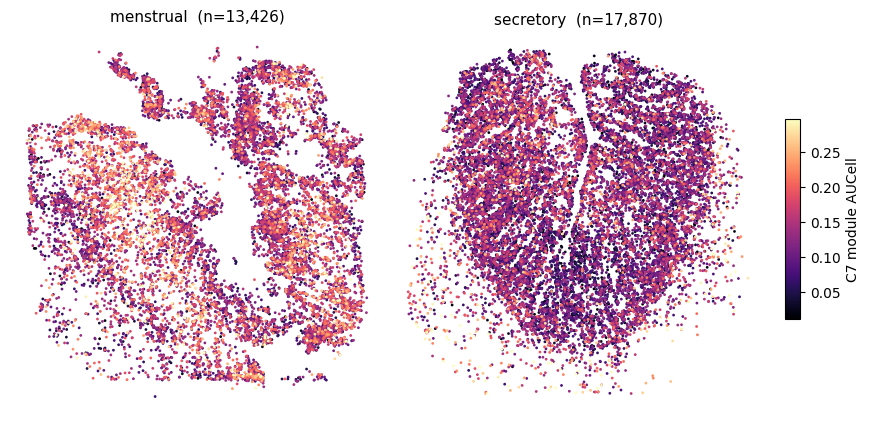

In [16]:
SCORE_COL   = "c7_module_auc"
TIMEPOINTS  = ["menstrual", "secretory"]
ROTATE_DEG  = {"menstrual": 270, "secretory": 90}   # per-timepoint CCW angle in data space
tp_col      = "timepoint"

assert SCORE_COL in human.obs, "run the AUCell section first (defines c7_module_auc)"


def rotate(x, y, deg, cx=None, cy=None):
    """Rotate points by `deg` about (cx, cy); defaults to their centroid."""
    cx = x.mean() if cx is None else cx
    cy = y.mean() if cy is None else cy
    t  = np.deg2rad(deg)
    xr = cx + (x - cx) * np.cos(t) - (y - cy) * np.sin(t)
    yr = cy + (x - cx) * np.sin(t) + (y - cy) * np.cos(t)
    return xr, yr


# Shared color scale across both panels (robust 1-99 pct over the plotted timepoints).
sel = human.obs[tp_col].isin(TIMEPOINTS)
vals = human.obs.loc[sel, SCORE_COL].to_numpy(float)
vals = vals[np.isfinite(vals)]
vmin, vmax = np.nanpercentile(vals, [1, 99])

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, tp in zip(axes, TIMEPOINTS):
    d = human.obs.loc[human.obs[tp_col] == tp,
                      ["x_um_dbscan", "y_um_dbscan", SCORE_COL]]
    x, y, s = (d[c].to_numpy(float) for c in d.columns)
    m = np.isfinite(x) & np.isfinite(y) & np.isfinite(s)
    x, y, s = x[m], y[m], s[m]

    x, y = rotate(x, y, ROTATE_DEG.get(tp, 0))    # per-timepoint; default 0 if unlisted
    o = np.argsort(s)                              # highest module activity on top

    pts = ax.scatter(x[o], y[o], c=s[o], cmap="magma", vmin=vmin, vmax=vmax,
                     s=4, linewidths=0, rasterized=True)
    ax.set_aspect("equal"); ax.invert_yaxis(); ax.set_axis_off()
    ax.set_title(f"{tp}  (n={m.sum():,})", fontsize=11)

fig.subplots_adjust(right=0.88, wspace=0.02)
cax = fig.add_axes([0.90, 0.30, 0.015, 0.40])
fig.colorbar(pts, cax=cax, label="C7 module AUCell")

fig.savefig("c7_module_auc_spatial.png", dpi=300, bbox_inches="tight")
plt.show()


In [18]:
# ============================================================================
# Module score via scanpy (Seurat-style) on log1p data
# ============================================================================
import scanpy as sc

SCORE_NAME = "c7_module_score"

# --- 1. Make sure we score LOG1P-normalized expression -----------------------
# score_genes expects log-normalized values (NOT raw counts, and NOT scaled/z-scored
# data — scaling breaks the control-gene binning). Detect what human.X holds and, if
# needed, build a log1p layer without disturbing whatever is already in .X.

def _looks_log1p(mat, cap=20.0):
    """Heuristic: log1p CP10k data is non-integer and has a small max (< ~cap)."""
    m = mat[:1000] if mat.shape[0] > 1000 else mat
    m = m.toarray() if hasattr(m, "toarray") else np.asarray(m)
    mx = float(np.nanmax(m)) if m.size else 0.0
    frac_int = np.mean(np.equal(np.mod(m[m != 0], 1), 0)) if np.any(m != 0) else 1.0
    return (mx < cap) and (frac_int < 0.99)   # non-integer & bounded -> already logged

X0 = human.X
if _looks_log1p(X0):
    SCORE_LAYER = None                      # score human.X directly
    print(f"human.X looks log1p (max={float(np.nanmax(X0.toarray() if hasattr(X0,'toarray') else X0)):.2f}); scoring .X directly.")
else:
    # Treat .X as counts: normalize + log1p into a dedicated layer, leave .X untouched.
    human.layers["counts_backup"] = human.X.copy()
    sc.pp.normalize_total(human, target_sum=1e4)
    sc.pp.log1p(human)
    human.layers["lognorm"] = human.X.copy()
    human.X = human.layers["counts_backup"]     # restore original .X
    SCORE_LAYER = "lognorm"
    print("human.X looked like counts; created a 'lognorm' layer (CP10k + log1p) and will score that.")

# --- 2. Restrict to module genes present in the data -------------------------
present = [g for g in C7_MODULE_GENES if g in set(human.var_names)]
missing = [g for g in C7_MODULE_GENES if g not in set(human.var_names)]
if missing:
    print(f"WARNING: {len(missing)} module gene(s) not in var_names, dropped: " + ", ".join(missing))
print(f"Scoring {len(present)} / {len(C7_MODULE_GENES)} module genes.")

# --- 3. Score --------------------------------------------------------------
sc.tl.score_genes(
    human,
    gene_list=present,
    score_name=SCORE_NAME,
    ctrl_size=50,          # docs: fine to bump toward len(present); 50 is the standard default
    layer=SCORE_LAYER,     # None -> uses .X
    use_raw=False,
    random_state=0,
)

print(human.obs[SCORE_NAME].describe())

human.X looks log1p (max=8.06); scoring .X directly.
Scoring 25 / 25 module genes.
count    47533.000000
mean         0.175929
std          0.184054
min         -0.312438
25%          0.044468
50%          0.155738
75%          0.286459
max          1.301967
Name: c7_module_score, dtype: float64


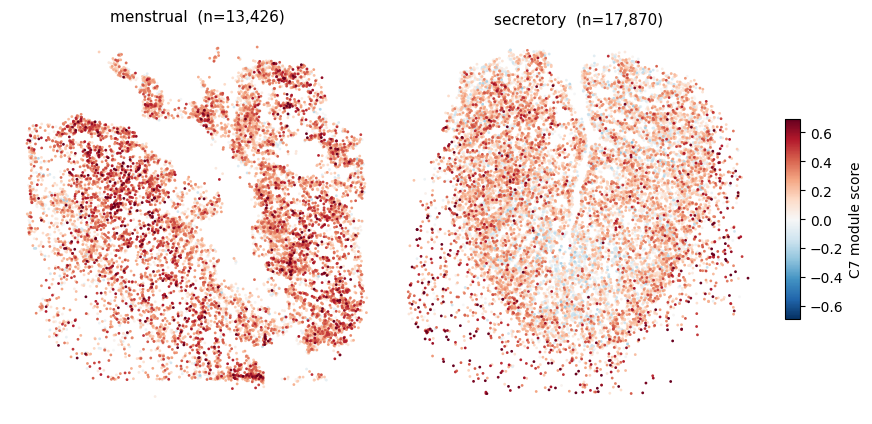

In [21]:
# ============================================================================
# Spatial plot of the C7 module score
# ============================================================================
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

SCORE_COL   = "c7_module_score"
TIMEPOINTS  = ["menstrual", "secretory"]
ROTATE_DEG  = {"menstrual": 270, "secretory": 90}   # per-timepoint CCW angle in data space
tp_col      = "timepoint"

assert SCORE_COL in human.obs, "run the scoring cell first (defines c7_module_score)"


def rotate(x, y, deg, cx=None, cy=None):
    """Rotate points by `deg` about (cx, cy); defaults to their centroid."""
    cx = x.mean() if cx is None else cx
    cy = y.mean() if cy is None else cy
    t  = np.deg2rad(deg)
    xr = cx + (x - cx) * np.cos(t) - (y - cy) * np.sin(t)
    yr = cy + (x - cx) * np.sin(t) + (y - cy) * np.cos(t)
    return xr, yr


# score_genes is signed (module minus control set), so use a 0-centered diverging map
# with a symmetric robust range — same convention as the stro7_margin figure.
sel  = human.obs[tp_col].isin(TIMEPOINTS)
vals = human.obs.loc[sel, SCORE_COL].to_numpy(float)
lim  = np.nanpercentile(np.abs(vals[np.isfinite(vals)]), 99)
norm = TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, tp in zip(axes, TIMEPOINTS):
    d = human.obs.loc[human.obs[tp_col] == tp,
                      ["x_um_dbscan", "y_um_dbscan", SCORE_COL]]
    x, y, s = (d[c].to_numpy(float) for c in d.columns)
    m = np.isfinite(x) & np.isfinite(y) & np.isfinite(s)
    x, y, s = x[m], y[m], s[m]

    x, y = rotate(x, y, ROTATE_DEG.get(tp, 0))    # per-timepoint; default 0 if unlisted
    o = np.argsort(np.abs(s))                      # strongest calls on top

    pts = ax.scatter(x[o], y[o], c=s[o], cmap="RdBu_r", norm=norm,
                     s=4, linewidths=0, rasterized=True)
    ax.set_aspect("equal"); ax.invert_yaxis(); ax.set_axis_off()
    ax.set_title(f"{tp}  (n={m.sum():,})", fontsize=11)

fig.subplots_adjust(right=0.88, wspace=0.02)
cax = fig.add_axes([0.90, 0.30, 0.015, 0.40])
fig.colorbar(pts, cax=cax, label="C7 module score")

fig.savefig("c7_module_score_spatial.png", dpi=300, bbox_inches="tight")
plt.show()

Saved: c7_genes_spatial_menstrual.png


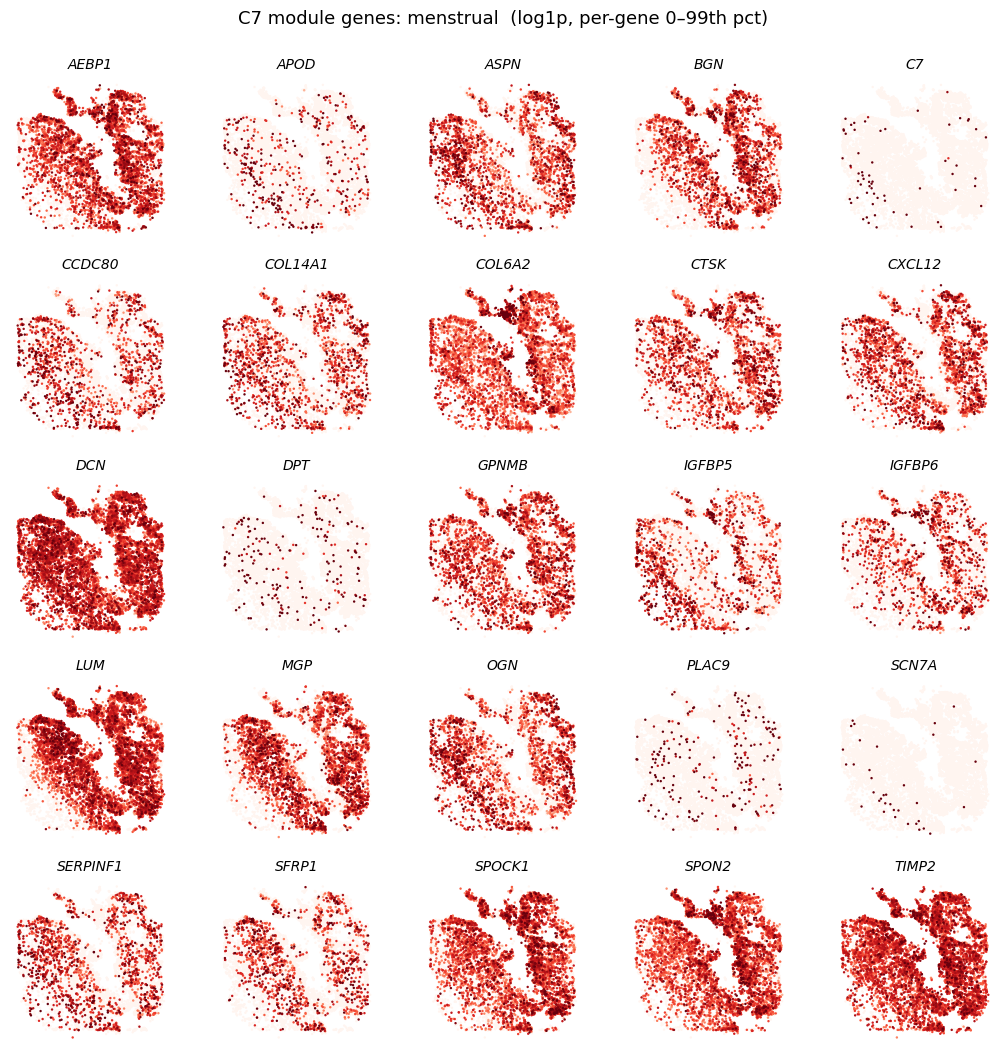

Saved: c7_genes_spatial_secretory.png


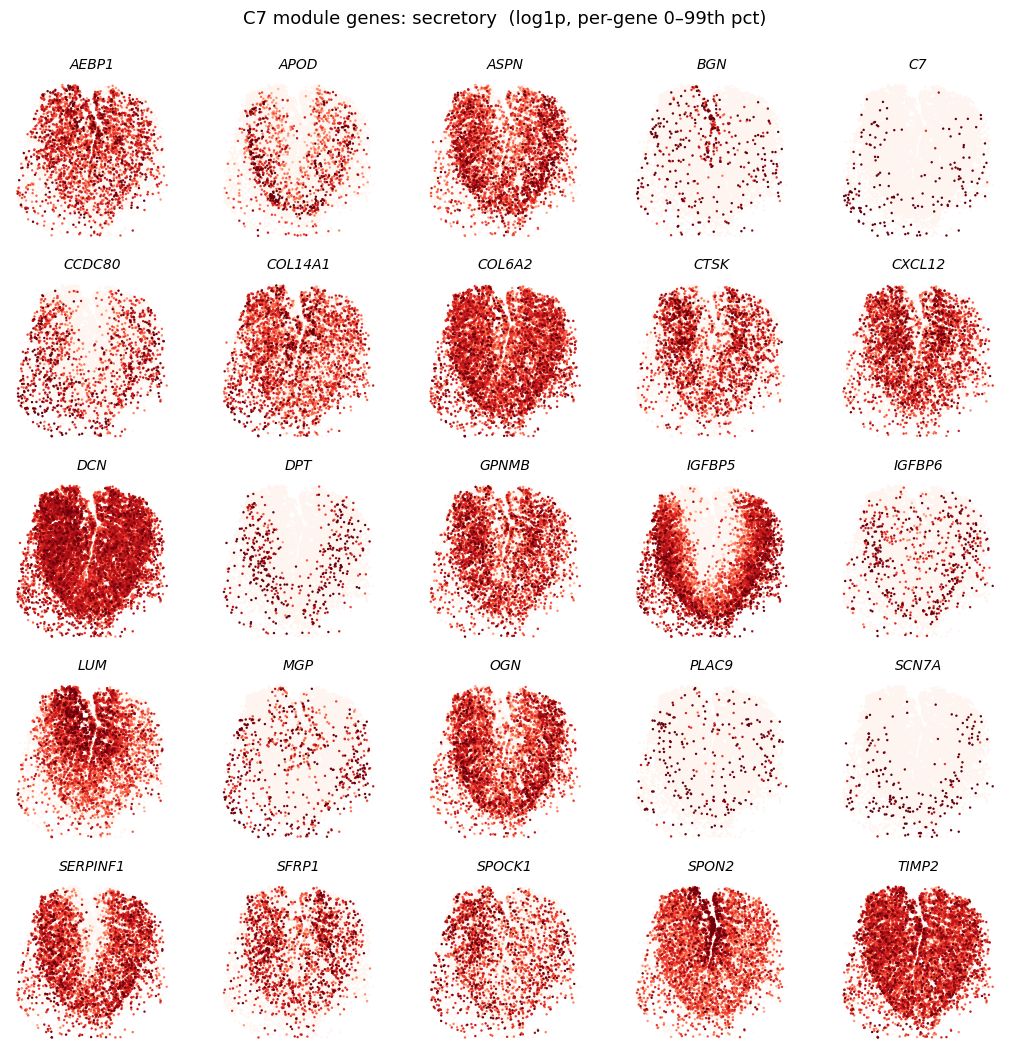

In [39]:
# ============================================================================
# Per-gene spatial expression (log1p) for the C7 module genes
# ============================================================================
import numpy as np
import matplotlib.pyplot as plt
from scipy import sparse

TIMEPOINTS = ["menstrual", "secretory"]
ROTATE_DEG = {"menstrual": 270, "secretory": 90}   # per-timepoint CCW angle in data space
tp_col     = "timepoint"
EXPR_LAYER = "log1p"      # set to None to use human.X

def rotate(x, y, deg, cx=None, cy=None):
    """Rotate points by `deg` about (cx, cy); defaults to their centroid."""
    cx = x.mean() if cx is None else cx
    cy = y.mean() if cy is None else cy
    t  = np.deg2rad(deg)
    xr = cx + (x - cx) * np.cos(t) - (y - cy) * np.sin(t)
    yr = cy + (x - cx) * np.sin(t) + (y - cy) * np.cos(t)
    return xr, yr

def _expr_vector(adata, gene, layer):
    """log1p expression for one gene as a 1-D float array (dense)."""
    j = adata.var_names.get_loc(gene)
    M = adata.layers[layer] if layer else adata.X
    col = M[:, j]
    col = col.toarray().ravel() if sparse.issparse(col) else np.asarray(col).ravel()
    return col.astype(float)

def plot_genes_spatial(adata, gene_list, timepoint, layer="log1p",
                       cmap="Reds", ncols=5, panel=2.1, pct=99, filename=None):
    """Grid of per-gene spatial expression maps for one timepoint.

    Expression is non-negative log1p, so a sequential colormap with a per-gene
    0-to-99th-percentile range is used (genes differ hugely in level, so a shared
    scale would black out the sparse ones like C7/CXCL12).
    """
    genes = [g for g in gene_list if g in set(adata.var_names)]
    missing = [g for g in gene_list if g not in set(adata.var_names)]
    if missing:
        print(f"[{timepoint}] dropped (not in var_names): {', '.join(missing)}")
    nrows = int(np.ceil(len(genes) / ncols))

    sub = adata[adata.obs[tp_col] == timepoint]
    x = sub.obs["x_um_dbscan"].to_numpy(float)
    y = sub.obs["y_um_dbscan"].to_numpy(float)
    finite_xy = np.isfinite(x) & np.isfinite(y)
    xr, yr = rotate(x[finite_xy], y[finite_xy], ROTATE_DEG.get(timepoint, 0))

    fig, axes = plt.subplots(nrows, ncols, figsize=(panel * ncols, panel * nrows))
    axes = np.atleast_1d(axes).ravel()

    for k, gene in enumerate(genes):
        ax = axes[k]
        s = _expr_vector(sub, gene, layer)[finite_xy]
        vmax = np.nanpercentile(s, pct) if np.any(s > 0) else 1.0
        vmax = vmax if vmax > 0 else 1.0
        o = np.argsort(s)                     # high expression drawn on top
        ax.scatter(xr[o], yr[o], c=s[o], cmap=cmap, vmin=0, vmax=vmax,
                   s=3, linewidths=0, rasterized=True)
        ax.set_aspect("equal"); ax.invert_yaxis(); ax.set_axis_off()
        ax.set_title(gene, fontsize=10, fontstyle="italic")

    for k in range(len(genes), len(axes)):   # hide unused panels
        axes[k].set_axis_off()

    fig.suptitle(f"C7 module genes: {timepoint}  (log1p, per-gene 0–{pct}th pct)",
                 fontsize=13, y=1.0)
    fig.tight_layout()
    if filename:
        fig.savefig(filename, dpi=200, bbox_inches="tight")
        print("Saved:", filename)
    plt.show()

for tp in TIMEPOINTS:
    plot_genes_spatial(human, C7_MODULE_GENES, tp, layer=EXPR_LAYER,
                       filename=f"c7_genes_spatial_{tp}.png")

## 6. (Optional) Save the scored object

Uncomment to persist the AnnData with the new `c7_module_auc` column.


In [23]:
# ============================================================================
# GASTON: subset to one sample, then geosketch
# ============================================================================
import os, torch, numpy as np
from geosketch import gs
from glmpca import glmpca
import gaston
from gaston import neural_net, dp_related, isodepth_scaling, cluster_plotting, model_selection

SAMPLE  = "secretory"                 # isodepth is per-sample; pick one
OUT_DIR = f"./gaston_human_{SAMPLE}"  # checkpoints land here
os.makedirs(f"{OUT_DIR}/nn_runs", exist_ok=True)
print("cuda:", torch.cuda.is_available())

adata = human[human.obs["timepoint"] == SAMPLE].copy()
adata = adata[~adata.obs["x_um_dbscan"].isna()].copy()     # need spatial coords
adata.obsm["X_spatial"] = adata.obs[["x_um_dbscan", "y_um_dbscan"]].to_numpy(float)

# geosketch needs an embedding — reuse whatever your object has
EMBED_KEY = "X_scVI"   # CHANGE if your embedding is named differently (check human.obsm)
assert EMBED_KEY in adata.obsm, f"no {EMBED_KEY!r} in obsm: {list(adata.obsm)}"

N = 6000
sketch_index = gs(adata.obsm[EMBED_KEY], N, replace=False)
adata_sketch = adata[sketch_index].copy()
print(f"{SAMPLE}: {adata.n_obs} cells -> sketch {adata_sketch.n_obs}")

cuda: True
secretory: 17870 cells -> sketch 6000


In [24]:
# ============================================================================
# GLM-PCA on raw counts, then train the GASTON neural net (GPU, slow)
# ============================================================================
from scipy.sparse import issparse

Xc = adata_sketch.layers["counts"]
Xc = Xc.toarray() if issparse(Xc) else np.asarray(Xc)
counts_mat = np.asarray(Xc, dtype=np.int64)
coords_mat = np.asarray(adata_sketch.obsm["X_spatial"], dtype=np.float64)
assert counts_mat.shape[0] == coords_mat.shape[0] == adata_sketch.n_obs

num_genes = 2000
top_idx = np.argsort(counts_mat.sum(axis=0))[-num_genes:]
glmpca_res = glmpca.glmpca(
    counts_mat[:, top_idx].T, 8, fam="poi", penalty=10, verbose=True,
    ctl={"maxIter": 30, "eps": 1e-4, "optimizeTheta": True},
)
A_glmpca = glmpca_res["factors"]

S_torch, A_torch = neural_net.load_rescale_input_data(coords_mat, A_glmpca)
device = "cuda" if torch.cuda.is_available() else "cpu"
for seed in range(3):
    seed_dir = f"{OUT_DIR}/nn_runs/rep{seed}"; os.makedirs(seed_dir, exist_ok=True)
    neural_net.train(
        S_torch, A_torch, S_hidden_list=[20, 20], A_hidden_list=[20, 20],
        epochs=10000, checkpoint=500, device=device, save_dir=seed_dir,
        optim="adam", seed=seed, save_final=True,
    )

Iteration: 0 | deviance=2.4128E+7
Iteration: 1 | deviance=2.4128E+7
Iteration: 2 | deviance=2.2555E+7
Iteration: 3 | deviance=2.1563E+7
Iteration: 4 | deviance=2.1192E+7
Iteration: 5 | deviance=2.0904E+7
Iteration: 6 | deviance=2.0701E+7
Iteration: 7 | deviance=2.0569E+7
Iteration: 8 | deviance=2.0485E+7
Iteration: 9 | deviance=2.0427E+7
Iteration: 10 | deviance=2.0384E+7
Iteration: 11 | deviance=2.0351E+7
Iteration: 12 | deviance=2.0324E+7
Iteration: 13 | deviance=2.0302E+7
Iteration: 14 | deviance=2.0285E+7
Iteration: 15 | deviance=2.0270E+7
Iteration: 16 | deviance=2.0257E+7
Iteration: 17 | deviance=2.0246E+7
Iteration: 18 | deviance=2.0237E+7
Iteration: 19 | deviance=2.0229E+7
Iteration: 20 | deviance=2.0222E+7
Iteration: 21 | deviance=2.0215E+7
Iteration: 22 | deviance=2.0209E+7
Iteration: 23 | deviance=2.0203E+7
Iteration: 24 | deviance=2.0198E+7
Iteration: 25 | deviance=2.0193E+7
Iteration: 26 | deviance=2.0189E+7
Iteration: 27 | deviance=2.0185E+7
Iteration: 28 | deviance=2.018

best: ./gaston_human_secretory/nn_runs/rep1 0.6544269919395447


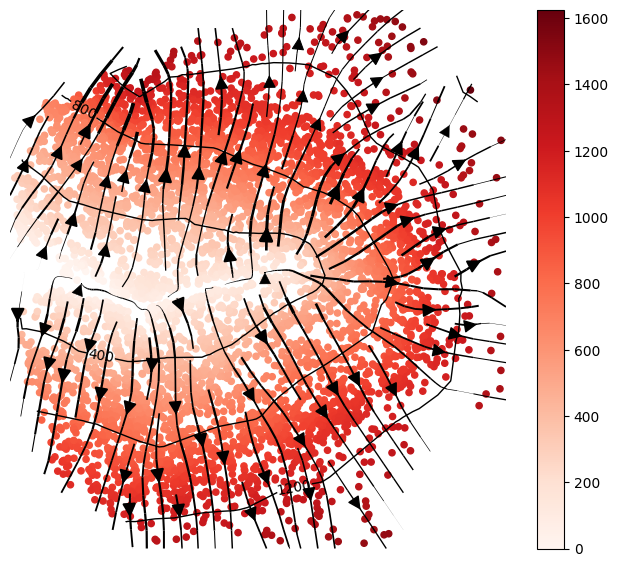

In [25]:
# ============================================================================
# Load best seed, extract + rescale isodepth
# ============================================================================
_orig = torch.load
torch.load = lambda *a, **kw: _orig(*a, **{**kw, "weights_only": False})
try:
    best_loss, best_dir = float("inf"), None
    for rep in sorted(os.listdir(f"{OUT_DIR}/nn_runs")):
        lf = f"{OUT_DIR}/nn_runs/{rep}/min_loss.txt"
        if not os.path.exists(lf): continue
        c = open(lf).read().strip()
        if c == "nan": continue
        if float(c) < best_loss: best_loss, best_dir = float(c), f"{OUT_DIR}/nn_runs/{rep}"
    print("best:", best_dir, best_loss)
    gaston_model = torch.load(f"{best_dir}/final_model.pt").cpu()
    A = torch.load(f"{best_dir}/Atorch.pt").cpu().detach().numpy()
    S = torch.load(f"{best_dir}/Storch.pt").cpu().detach().numpy()
finally:
    torch.load = _orig

num_layers = 4     # CHANGE per the LL curve / biology, as in your other notebook
gaston_isodepth, gaston_labels = dp_related.get_isodepth_labels(gaston_model, A, S, num_layers)
# flip if the gradient runs functionalis->basalis (check plot_isodepth):
# gaston_isodepth = gaston_isodepth.max() - gaston_isodepth

scale_factor = 64 / 100     # slide-tags convention, as in your other notebook
gaston_isodepth = isodepth_scaling.adjust_isodepth(
    gaston_isodepth, gaston_labels, coords_mat,
    q_vals=[0.1]*num_layers, scale_factor=scale_factor,
)
cluster_plotting.plot_isodepth(gaston_isodepth, S, gaston_model,
                               figsize=(8,7), streamlines=True, cmap="Reds")

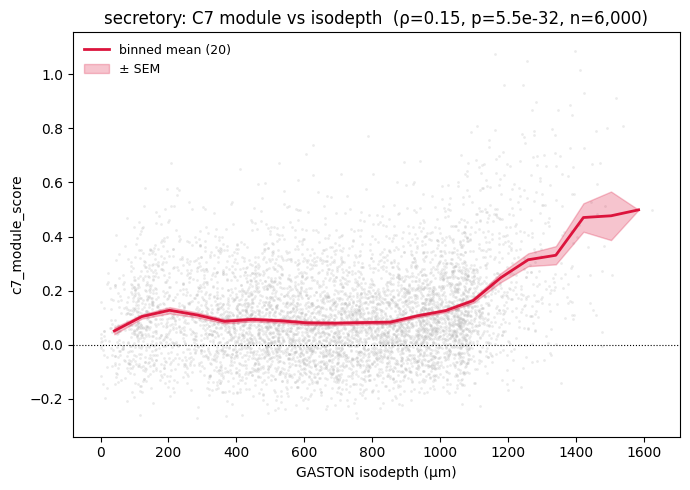

In [26]:
# ============================================================================
# C7 module score as a function of GASTON isodepth
# ============================================================================
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, binned_statistic

SCORE_COL, N_BINS = "c7_module_score", 20   # use "c7_module_auc" if you prefer the AUCell score

assert len(gaston_isodepth) == adata_sketch.n_obs, "isodepth must align to the sketch"
adata_sketch.obs["gaston_isodepth"] = np.asarray(gaston_isodepth, float)

# the sketch may not carry the score column — re-score on the sketch to be safe
if SCORE_COL not in adata_sketch.obs:
    import scanpy as sc
    present = [g for g in C7_MODULE_GENES if g in set(adata_sketch.var_names)]
    sc.tl.score_genes(adata_sketch, present, score_name=SCORE_COL,
                      ctrl_size=50, layer="log1p", use_raw=False, random_state=0)

iso_v = adata_sketch.obs["gaston_isodepth"].to_numpy(float)
sc_v  = adata_sketch.obs[SCORE_COL].to_numpy(float)
ok = np.isfinite(iso_v) & np.isfinite(sc_v); iso_v, sc_v = iso_v[ok], sc_v[ok]

rho, pval = spearmanr(iso_v, sc_v)
bm, edges, _ = binned_statistic(iso_v, sc_v, "mean",  bins=N_BINS)
bs, _, _     = binned_statistic(iso_v, sc_v, "std",   bins=N_BINS)
bc, _, _     = binned_statistic(iso_v, sc_v, "count", bins=N_BINS)
ctr = 0.5*(edges[:-1]+edges[1:])
sem = np.divide(bs, np.sqrt(bc), out=np.full_like(bs, np.nan), where=bc>0)

fig, ax = plt.subplots(figsize=(7,5))
ax.scatter(iso_v, sc_v, s=4, c="0.7", alpha=0.25, linewidths=0, rasterized=True)
ax.plot(ctr, bm, color="crimson", lw=2, label=f"binned mean ({N_BINS})")
ax.fill_between(ctr, bm-sem, bm+sem, color="crimson", alpha=0.25, label="± SEM")
ax.axhline(0, color="k", lw=0.8, ls=":")
ax.set_xlabel("GASTON isodepth (µm)"); ax.set_ylabel(SCORE_COL)
ax.set_title(f"{SAMPLE}: C7 module vs isodepth  (ρ={rho:.2f}, p={pval:.1e}, n={ok.sum():,})")
ax.legend(frameon=False, fontsize=9)
fig.tight_layout(); fig.savefig(f"c7_module_vs_isodepth_{SAMPLE}.png", dpi=200, bbox_inches="tight")
plt.show()

In [47]:
# ============================================================================
# GASTON: subset to one sample, then geosketch
# ============================================================================
import os, torch, numpy as np
from geosketch import gs
from glmpca import glmpca
import gaston
from gaston import neural_net, dp_related, isodepth_scaling, cluster_plotting, model_selection

SAMPLE  = "menstrual"                 # isodepth is per-sample; pick one
OUT_DIR = f"./gaston_human_{SAMPLE}"  # checkpoints land here
os.makedirs(f"{OUT_DIR}/nn_runs", exist_ok=True)
print("cuda:", torch.cuda.is_available())

adata = human[human.obs["timepoint"] == SAMPLE].copy()
adata = adata[~adata.obs["x_um_dbscan"].isna()].copy()     # need spatial coords
adata.obsm["X_spatial"] = adata.obs[["x_um_dbscan", "y_um_dbscan"]].to_numpy(float)

# geosketch needs an embedding — reuse whatever your object has
EMBED_KEY = "X_scVI"   # CHANGE if your embedding is named differently (check human.obsm)
assert EMBED_KEY in adata.obsm, f"no {EMBED_KEY!r} in obsm: {list(adata.obsm)}"

N = 3000
sketch_index = gs(adata.obsm[EMBED_KEY], N, replace=False)
adata_sketch = adata[sketch_index].copy()
print(f"{SAMPLE}: {adata.n_obs} cells -> sketch {adata_sketch.n_obs}")

cuda: True
menstrual: 13426 cells -> sketch 3000


In [48]:
# ============================================================================
# GLM-PCA on raw counts, then train the GASTON neural net (GPU, slow)
# ============================================================================
from scipy.sparse import issparse

Xc = adata_sketch.layers["counts"]
Xc = Xc.toarray() if issparse(Xc) else np.asarray(Xc)
counts_mat = np.asarray(Xc, dtype=np.int64)
coords_mat = np.asarray(adata_sketch.obsm["X_spatial"], dtype=np.float64)
assert counts_mat.shape[0] == coords_mat.shape[0] == adata_sketch.n_obs

num_genes = 2000
top_idx = np.argsort(counts_mat.sum(axis=0))[-num_genes:]
glmpca_res = glmpca.glmpca(
    counts_mat[:, top_idx].T, 8, fam="poi", penalty=10, verbose=True,
    ctl={"maxIter": 30, "eps": 1e-4, "optimizeTheta": True},
)
A_glmpca = glmpca_res["factors"]

S_torch, A_torch = neural_net.load_rescale_input_data(coords_mat, A_glmpca)
device = "cuda" if torch.cuda.is_available() else "cpu"
for seed in range(3):
    seed_dir = f"{OUT_DIR}/nn_runs/rep{seed}"; os.makedirs(seed_dir, exist_ok=True)
    neural_net.train(
        S_torch, A_torch, S_hidden_list=[20, 20], A_hidden_list=[20, 20],
        epochs=10000, checkpoint=500, device=device, save_dir=seed_dir,
        optim="adam", seed=seed, save_final=True,
    )

Iteration: 0 | deviance=1.2084E+7
Iteration: 1 | deviance=1.2084E+7
Iteration: 2 | deviance=1.1369E+7
Iteration: 3 | deviance=1.0434E+7
Iteration: 4 | deviance=1.0141E+7
Iteration: 5 | deviance=1.0011E+7
Iteration: 6 | deviance=9.9489E+6
Iteration: 7 | deviance=9.9161E+6
Iteration: 8 | deviance=9.8963E+6
Iteration: 9 | deviance=9.8827E+6
Iteration: 10 | deviance=9.8722E+6
Iteration: 11 | deviance=9.8634E+6
Iteration: 12 | deviance=9.8554E+6
Iteration: 13 | deviance=9.8479E+6
Iteration: 14 | deviance=9.8408E+6
Iteration: 15 | deviance=9.8340E+6
Iteration: 16 | deviance=9.8277E+6
Iteration: 17 | deviance=9.8219E+6
Iteration: 18 | deviance=9.8166E+6
Iteration: 19 | deviance=9.8118E+6
Iteration: 20 | deviance=9.8075E+6
Iteration: 21 | deviance=9.8039E+6
Iteration: 22 | deviance=9.8007E+6
Iteration: 23 | deviance=9.7981E+6
Iteration: 24 | deviance=9.7959E+6
Iteration: 25 | deviance=9.7940E+6
Iteration: 26 | deviance=9.7925E+6
Iteration: 27 | deviance=9.7911E+6
Iteration: 28 | deviance=9.790

best: ./gaston_human_menstrual/nn_runs/rep2 0.7809579968452454


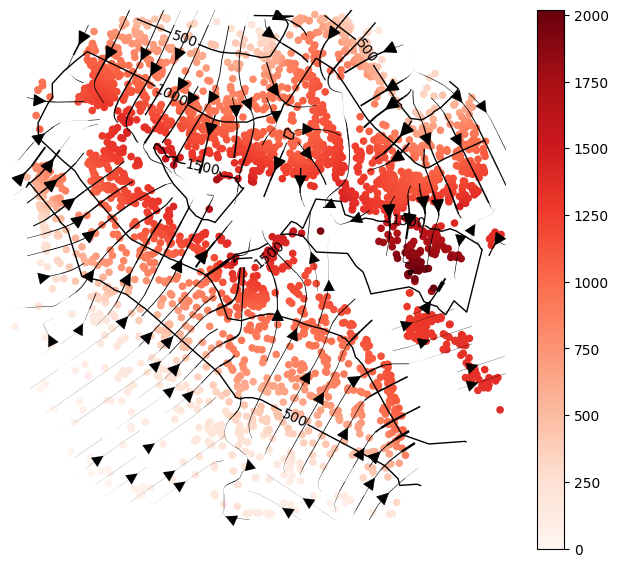

In [49]:
# ============================================================================
# Load best seed, extract + rescale isodepth
# ============================================================================
_orig = torch.load
torch.load = lambda *a, **kw: _orig(*a, **{**kw, "weights_only": False})
try:
    best_loss, best_dir = float("inf"), None
    for rep in sorted(os.listdir(f"{OUT_DIR}/nn_runs")):
        lf = f"{OUT_DIR}/nn_runs/{rep}/min_loss.txt"
        if not os.path.exists(lf): continue
        c = open(lf).read().strip()
        if c == "nan": continue
        if float(c) < best_loss: best_loss, best_dir = float(c), f"{OUT_DIR}/nn_runs/{rep}"
    print("best:", best_dir, best_loss)
    gaston_model = torch.load(f"{best_dir}/final_model.pt").cpu()
    A = torch.load(f"{best_dir}/Atorch.pt").cpu().detach().numpy()
    S = torch.load(f"{best_dir}/Storch.pt").cpu().detach().numpy()
finally:
    torch.load = _orig

num_layers = 4     # CHANGE per the LL curve / biology, as in your other notebook
gaston_isodepth, gaston_labels = dp_related.get_isodepth_labels(gaston_model, A, S, num_layers)
# flip if the gradient runs functionalis->basalis (check plot_isodepth):
# gaston_isodepth = gaston_isodepth.max() - gaston_isodepth

scale_factor = 64 / 100     # slide-tags convention, as in your other notebook
gaston_isodepth = isodepth_scaling.adjust_isodepth(
    gaston_isodepth, gaston_labels, coords_mat,
    q_vals=[0.1]*num_layers, scale_factor=scale_factor,
)
cluster_plotting.plot_isodepth(gaston_isodepth, S, gaston_model,
                               figsize=(8,7), streamlines=True, cmap="Reds")

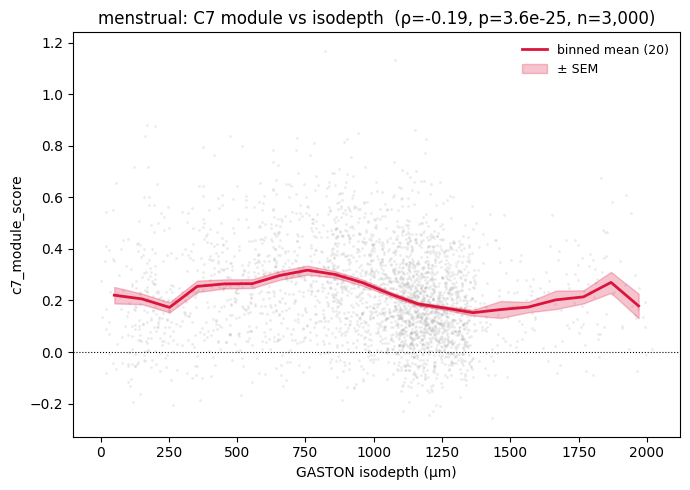

In [50]:
# ============================================================================
# C7 module score as a function of GASTON isodepth
# ============================================================================
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, binned_statistic

SCORE_COL, N_BINS = "c7_module_score", 20   # use "c7_module_auc" if you prefer the AUCell score

assert len(gaston_isodepth) == adata_sketch.n_obs, "isodepth must align to the sketch"
adata_sketch.obs["gaston_isodepth"] = np.asarray(gaston_isodepth, float)

# the sketch may not carry the score column — re-score on the sketch to be safe
if SCORE_COL not in adata_sketch.obs:
    import scanpy as sc
    present = [g for g in C7_MODULE_GENES if g in set(adata_sketch.var_names)]
    sc.tl.score_genes(adata_sketch, present, score_name=SCORE_COL,
                      ctrl_size=50, layer="log1p", use_raw=False, random_state=0)

iso_v = adata_sketch.obs["gaston_isodepth"].to_numpy(float)
sc_v  = adata_sketch.obs[SCORE_COL].to_numpy(float)
ok = np.isfinite(iso_v) & np.isfinite(sc_v); iso_v, sc_v = iso_v[ok], sc_v[ok]

rho, pval = spearmanr(iso_v, sc_v)
bm, edges, _ = binned_statistic(iso_v, sc_v, "mean",  bins=N_BINS)
bs, _, _     = binned_statistic(iso_v, sc_v, "std",   bins=N_BINS)
bc, _, _     = binned_statistic(iso_v, sc_v, "count", bins=N_BINS)
ctr = 0.5*(edges[:-1]+edges[1:])
sem = np.divide(bs, np.sqrt(bc), out=np.full_like(bs, np.nan), where=bc>0)

fig, ax = plt.subplots(figsize=(7,5))
ax.scatter(iso_v, sc_v, s=4, c="0.7", alpha=0.25, linewidths=0, rasterized=True)
ax.plot(ctr, bm, color="crimson", lw=2, label=f"binned mean ({N_BINS})")
ax.fill_between(ctr, bm-sem, bm+sem, color="crimson", alpha=0.25, label="± SEM")
ax.axhline(0, color="k", lw=0.8, ls=":")
ax.set_xlabel("GASTON isodepth (µm)"); ax.set_ylabel(SCORE_COL)
ax.set_title(f"{SAMPLE}: C7 module vs isodepth  (ρ={rho:.2f}, p={pval:.1e}, n={ok.sum():,})")
ax.legend(frameon=False, fontsize=9)
fig.tight_layout(); fig.savefig(f"c7_module_vs_isodepth_{SAMPLE}.png", dpi=200, bbox_inches="tight")
plt.show()